<a href="https://colab.research.google.com/github/kimberly-li103/Four-in-a-Row/blob/main/Main_Four_In_A_Row.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Build an Unbeatable AI: Tic-Tac-Toe
Welcome to your first AI project! We are going to build a Tic-Tac-Toe game using the **Minimax** algorithm.
Your goal is to fill in the `TODO` sections in the code cells below. Test each cell by pressing the "Play" button before moving to the next one!
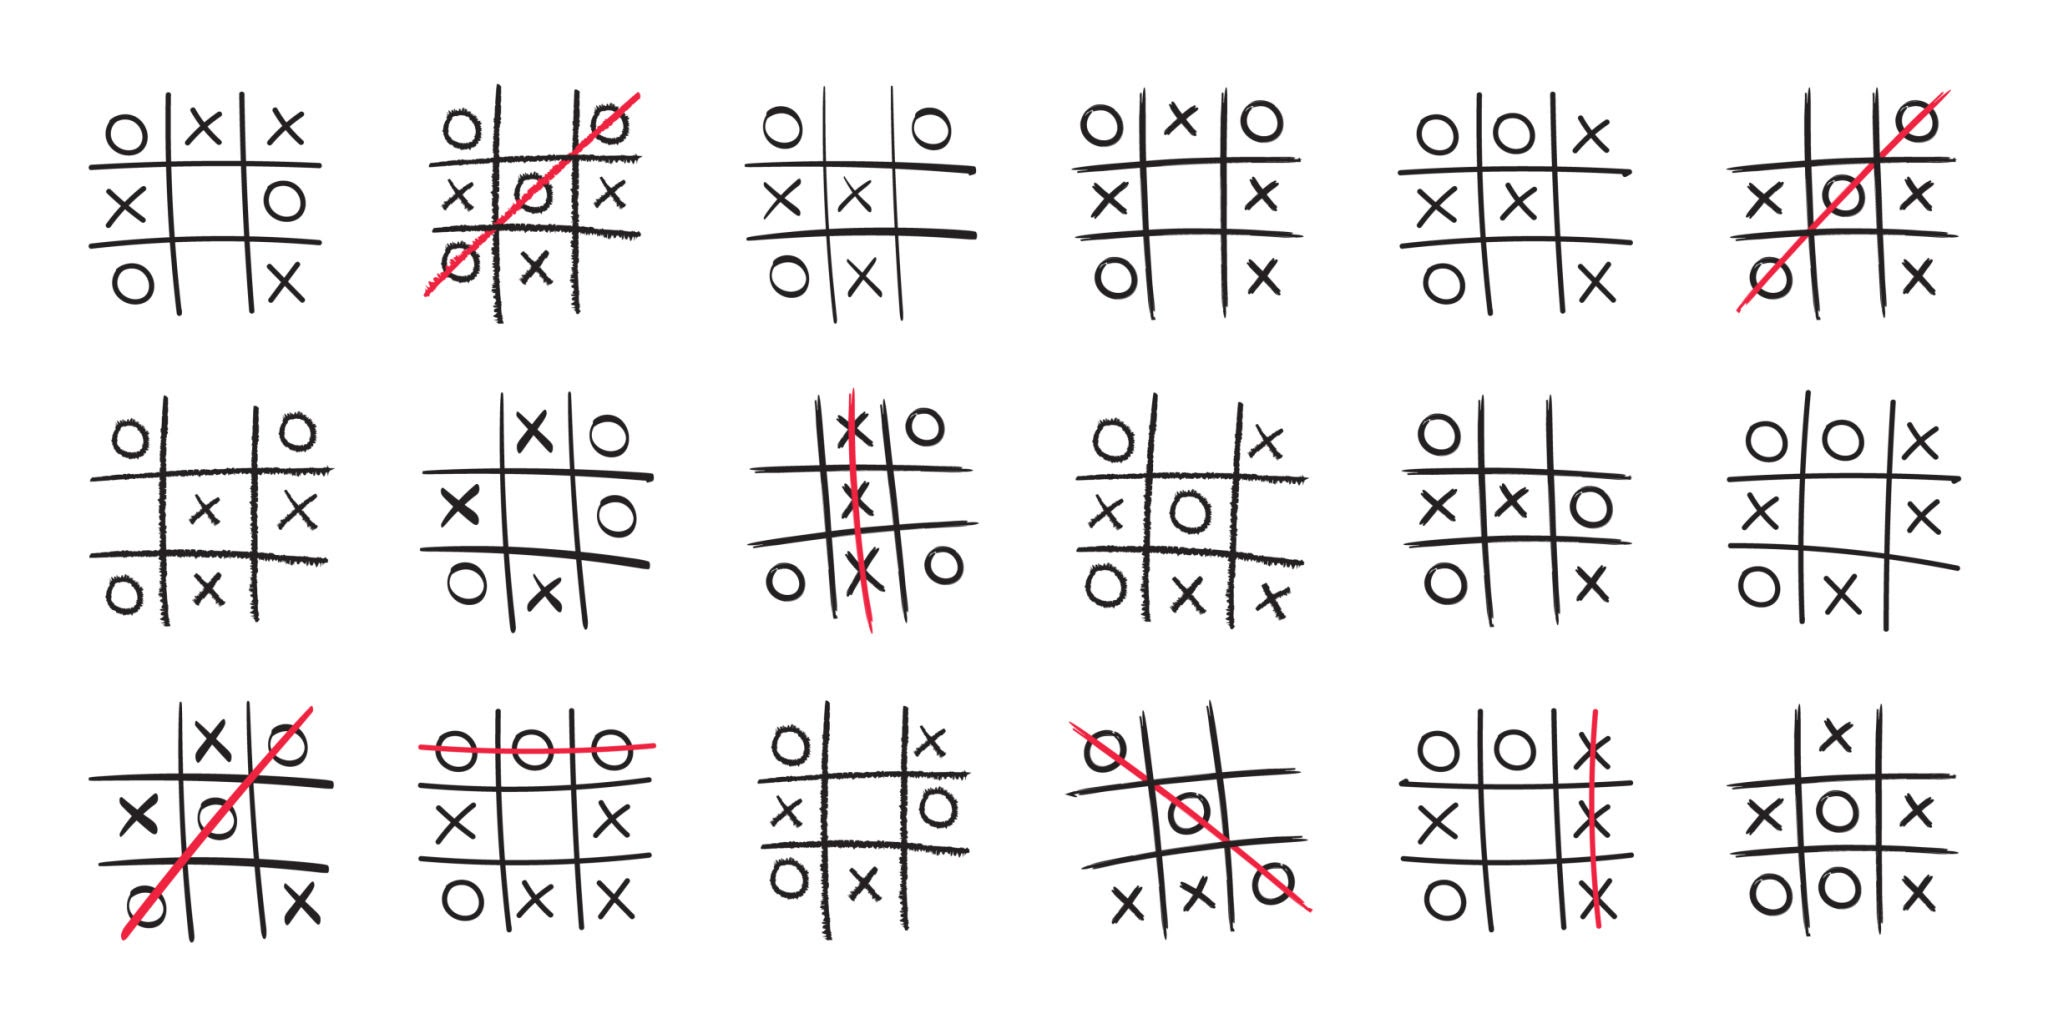

In [ ]:
# The board is a list of 9 spaces. Indexes 0-8.
import numpy as np
#rng = np.random.default_rng()
#array_2d_wide = rng.permutation([0, 1, 2]).reshape(1, 3)
#print(array_2d_wide)
#board = np.zeros((6,7))

# Accessing an element uses a cleaner comma syntax: array[row, column]
#print(np_matrix[0, 1])  # Outputs: 2

# Create a 3x3 grid of zeros instantly
#print(board_matrix)


def print_board(b):
  row,col = b.shape
  for r in range (row):
    for c in range (col):
      if b[r,c] == 0:
        print(" ", "|", end="")
      elif b[r,c] == 1:
        print("X", "|", end="")
      elif b[r,c] == 2:
        print("O", "|", end="")
      #print(b[r,c],"|", end="")
    print("\n-------------------------------")


def is_board_full(b):
  row,col = b.shape
  for r in range (row):
    for c in range (col):
      if b[r,c] == 0:
        return False
  return True


def get_empty_col(b):
  #open_rows=[]
  b_state = b.state
  open_cols=[]
  row,col = b_state.shape
  for c in range (col):
    for r in range (row):
      if b_state[r,c] == 0:
        open_cols.append(c)
      break
  return open_cols


## 📏 Game Logic
Before the AI can think, it needs to know how to win. The function below should check all 8 possible ways to win Tic-Tac-Toe.

In [ ]:
mock=[[0,0,0,0,0,0,0,0],
      [0,0,0,1,0,0,0,0],
      [0,0,0,0,1,0,0,0],
      [0,0,0,0,0,1,0,0],
      [0,0,0,0,0,0,1,0]]

# the plan for my function is

def check_horizontal(one_row, player, c):
  # check horizontally, return True if connected 4 is found
  col = one_row.shape[0]
  horizontal_count = 1
  #check left
  for x in range (1,4):
    if c-x >= 0 and one_row[c-x] == player:
      horizontal_count = horizontal_count+1
    else:
      break
  if horizontal_count == 4:
      return True
  #check right
  for x in range (1,4):
    if c+x < col  and one_row[c+x] == player:
      horizontal_count = horizontal_count+1
    else:
      break
  if horizontal_count == 4:
      return True
  return False

# check vertically, return True. ..
#only need to check check
def check_vertical(one_col, player, r):
  row = one_col.shape[0]
  vertical_count = 1
  #check down
  for x in range (1,4):
    if r+x < row  and one_col[r+x] == player:
      vertical_count = vertical_count + 1
    else:
      break
  if vertical_count == 4:
    return True
  return False

# check diagnoally, return True ..
def check_diagonal(b, player, r, c):
  row, col = b.shape
  diagonal_count = 1
  #check down diagonal
  for x in range (1,4):
    if c+x < col and r+x < row and b[r+x, c+x] == player :
      diagonal_count = diagonal_count+1
    else:
      break
  if diagonal_count == 4:
      return True
  #check up diagonal
  for x in range (1,4):
    if c-x >= 0 and r-x >=0 and b[r-x, c-x] == player :
      diagonal_count = diagonal_count+1
    else:
      break
  if diagonal_count == 4:
      return True
  return False

# check anti-diagonally, return True...
def check_anti_diagonal(b, player, r, c):
  row, col = b.shape
  anti_diagonal_count = 1
  #check down diagonal
  for x in range (1,4):
    if c-x >= 0 and r+x < row and b[r+x, c-x] == player :
      anti_diagonal_count = anti_diagonal_count+1
    else:
      break
  if anti_diagonal_count == 4:
      return True
  #check up diagonal
  for x in range (1,4):
    if c+x < col and r-x >=0 and b[r-x, c+x] == player :
      anti_diagonal_count = anti_diagonal_count + 1
    else:
      break
  if anti_diagonal_count == 4:
      return True
  return False

def check_winner(b, player, r, c):
  assert b[r,c] == player
  winner_found = check_horizontal(b[r], player, c)
  if winner_found:
    return True
  winner_found = check_vertical(b[:,c], player, r)
  if winner_found:
    return True
  winner_found = check_diagonal(b, player, r, c)
  if winner_found:
    return True
  return check_anti_diagonal(b, player, r, c)

check_winner(np.array(mock), 1, 1, 3)

True

## 🤖 The Navie AI
The most naive player is to make a random move by picking a square on the board without "thinking". This is the first AI we build, and we will do something smarter in the future.

In [ ]:
import random
def get_random_col(b):
  empty_cols = []
  row,col = b.state.shape
  for c in range(col):
    for r in range(row):
      if b.state[row-1-r,c] == 0:
        empty_cols.append(c)
        break
  random_col = random.choice(empty_cols)
  return random_col

def find_slot(b, c, player_index):
  row,col = b.shape
  for r in range(row):
    if b[row-1-r,c] == 0:
      b[row-1-r,c] = player_index
      return True, row-1-r
  return False, row-1-r


## 🎮 Play the Game!
Run the cell below to start the game loop and test your AI. If you coded the `TODO`s correctly, you will never be able to beat it!

In [ ]:
#MUST DO
def play_game():
    global board
    board = np.zeros((6,7)) # Reset board
    print("Welcome to Unbeatable Four In A Row or Connect Four!")

    while True:
        print_board(board)
        row,col = board.shape
        # Human Turn
        slot_found = False

        while not slot_found:
          col_move = int(input("Enter your move in column 0-6: "))
          slot_found, human_row_move = find_slot(board, col_move, 1)
          if not slot_found:
            print("Column is full! Try again.")


        if check_winner(board, 1, human_row_move, col_move):
            print_board(board)
            print("You won! (Wait, the AI must be broken...)")
            break
        if is_board_full(board):
            print_board(board)
            print("Tie game!")
            break

        #AI Turn
        print("AI is calculating every possible future...")
        slot_found = False
        while not slot_found:
          random_col = get_random_col(board)
          slot_found, ai_row_move = find_slot(board, random_col, 2)


        if check_winner(board, 2, ai_row_move, random_col):
            print_board(board)
            print("AI wins! Better luck next time.")
            break
        if is_board_full(board):
            print_board(board)
            print("Tie game!")
            break

# Trigger the game
play_game()

Welcome to Unbeatable Four In A Row or Connect Four!
  |  |  |  |  |  |  |
-------------------------------
  |  |  |  |  |  |  |
-------------------------------
  |  |  |  |  |  |  |
-------------------------------
  |  |  |  |  |  |  |
-------------------------------
  |  |  |  |  |  |  |
-------------------------------
  |  |  |  |  |  |  |
-------------------------------


KeyboardInterrupt: Interrupted by user

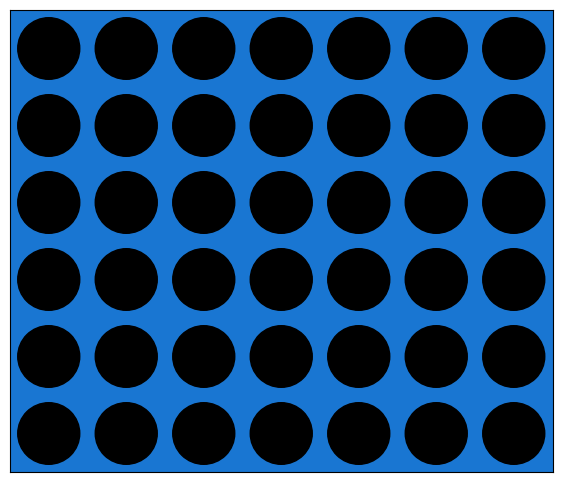

KeyboardInterrupt: Interrupted by user

In [ ]:
# Scafold code for object-oriented programming for connect4
# Please implement three classes: Board, HumanPlayer, and MachinePlayer.
# Both HumanPlayer and MachinePlayer inherit from a class named Player.
# From the code below, find out what methods each class needs to implement.
from IPython.display import clear_output
import matplotlib.pyplot as plt
import copy

class Board:
  def __init__(self, row, col):
    self.state = np.zeros((row,col))
  def display(self):
    print_board(self.state)

  def is_full(self):
    return is_board_full(self.state)

  def apply_move(self, selected_col, player_id):
    # if the col is out of 0-6
    row, col = self.state.shape
    if selected_col < 0 or selected_col > col-1:
      print("Selected Column is out of range! Try again.")
      return False, 0
    # if move is possible in row
    # apply move
    slot_found, row_move = find_slot(self.state, selected_col, player_id)
    if not slot_found:
      print("Column is full! Try again.")
    return slot_found, row_move

  def check_winner(self, player_id, row_move, col_move):
    return check_winner(self.state, player_id, row_move, col_move)

  def draw_board(self):
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.set_facecolor('#1976D2')
    ax.set_xlim(0,7)
    ax.set_ylim(0,6)
    for row in range (0,6):
      for col in range (0,7):
        if self.state[row, col] == 1:
            color = '#D32F2F'
        elif self.state[row, col] == 2:
            color = '#FBC02D'
        else:
          color = 'black'
        circle = plt.Circle((col + 0.5, 5-row + 0.5), 0.4, color=color)
        ax.add_patch(circle)
    plt.xticks([])
    plt.yticks([])
    plt.show()
    plt.pause(0.1)


class Player:
  def __init__(self, name, id):
    self.name = name
    self.id= id

class HumanPlayer(Player):
  def get_move(self, board):
    col_move = int(input("Enter your move in column 0-6: "))
    return col_move

class MachinePlayer(Player):
  def get_move(self, board):
    potential_opp_wins = 0
    opponent_id = 2 if self.id == 1 else 1   # FIX: don't hard-code opponent as 1
    for i in range (0, 7):
      if board.state[0, i] != 0:   # FIX: skip full columns
        continue
      #generate copy of array
      sim_board = copy.deepcopy(board)
      #place own piece and check winner
      is_success, row_chosen = sim_board.apply_move(i, self.id)
      if is_success:
        machine_success = sim_board.check_winner(self.id, row_chosen, i)
      if machine_success:
        return i
      sim_board.state[row_chosen, i] = 0
      #place opponent and check winner
      is_success, row_chosen = sim_board.apply_move(i, opponent_id)
      if is_success:
        person_success = sim_board.check_winner(opponent_id, row_chosen, i)
      if person_success:
        best_move_forPerson = i
        potential_opp_wins += 1
    if potential_opp_wins > 0:   # FIX: moved out of the loop (col 6 may be skipped)
      return best_move_forPerson
    random_col = get_random_col(board)
    return random_col


board = Board(6, 7)
players = [HumanPlayer("Human", 1), MachinePlayer("Machine", 2)]
player_index = 0

board.draw_board()
winner_found = False

while(not board.is_full()):
  current_player = players[player_index]
  is_success = False
  while not is_success:
    col_chosen = current_player.get_move(board)
    is_success, row_chosen = board.apply_move(col_chosen, current_player.id)
  if player_index == 1:
    board.draw_board()
  if board.check_winner(current_player.id, row_chosen, col_chosen):
    print(current_player.name + " won!")
    winner_found = True
    break
  player_index  = (player_index + 1) % 2
if not winner_found:
  print("No one wins")



#The 1-Step Lookahead (Algorithmic Logic) Oct 11, 2026

##The Goal: Upgrade the random agent so it never misses an immediate win or an immediate block.

The Implementation: Before making a random move, the agent loops through all 7 columns. It temporarily drops a piece in a copy of the NumPy matrix. If that move triggers her check_win function, it plays that column. If not, it simulates the opponent's piece; if the opponent would win there, it plays there to block.

## Phase 2: Upgrading the Engine (Visual Rendering) Oct 23, 2026
Matrix text outputs (`| 1 | 2 | 0 |`) are great for debugging, but a real AI engineer visualizes their data. We are going to teach the `Board` class how to draw itself using `matplotlib`.

> Add blockquote



**Your Task:** Replace your old text-based `display` method with this new `draw_board` method inside your `Board` class.

In [ ]:
# TODO: Import clear_output from IPython.display
  # TODO: Import matplotlib.pyplot as plt
import clear_output from IPython.display
import matplotlib.pyplot as plt

def draw_board(self):
  """
  Draws the current board state using matplotlib circles instead of ASCII text.
  """


  # TODO: Call clear_output(wait=True) so the board overwrites itself instead of scrolling forever

  # TODO: Create a figure and axis using plt.subplots(figsize=(7, 6))

  # TODO: Set the background color of the axis (ax) to a nice Connect 4 blue (e.g., '#1976D2')
  # TODO: Set the x-limits to (0, 7) and the y-limits to (0, 6)

  # TODO: Write a nested for-loop to iterate through all 6 rows and 7 columns of self.state
      # 1. Check the value of the piece at self.state[row, col]
      # 2. If it's 1, set color = 'red'. If 2, color = 'yellow'. Else, color = 'white'.

      # 3. Calculate the Cartesian (x, y) coordinates for the circle.
      # Hint: x = col + 0.5, y = 5 - row + 0.5

      # 4. Create a plt.Circle at those (x, y) coordinates with a radius of 0.4
      # 5. Add the circle to the axis using ax.add_patch(circle)

  # TODO: Hide the axis ticks so it looks like a game board (ax.set_xticks([]) and ax.set_yticks([]))

  # TODO: Call plt.show()

## Phase 1: Building the AI's Experience (Data Generation)
To train our PyTorch neural network to play Connect 4, it needs memories to learn from. Instead of playing thousands of games manually, we will make two `MachinePlayer` agents play against each other in a fast, silent loop!

**Your Task:** Complete the `generate_dataset` function below. You need to record the `board.state` at every single turn, figure out who won, and save those experiences as a dataset.

*   `X` will be our inputs (the board matrices).
*   `y` will be our labels (`+1` for Player 1 win, `-1` for Player 2 win).

In [ ]:
import numpy as np

def generate_dataset(num_games=1000):
    print(f"Starting self-play to generate {num_games} games...")
    dataset_X = []  # To store the board states (the features)
    dataset_Y = []  # To store the game outcomes (the labels)

    for game_idx in range(num_games):
      game_history = [] # Temporarily stores the board states for just this one game
      board = Board(6, 7)
      players= [MachinePlayer("Machine_1", 1), MachinePlayer("Machine_2", 2)]
      player_index = 0
      winner_found = False
      score=0

      while(not board.is_full()):
        current_player = players[player_index]
        is_success = False
        while not is_success:
          col_chosen = current_player.get_move(board)
          is_success, row_chosen = board.apply_move(col_chosen, current_player.id)
        game_history.append(board.state.copy())
        if board.check_winner(current_player.id, row_chosen, col_chosen):
          winner_found = True
          if current_player.id == 1:   # FIX: player_index is never 2
            score = +1
          else:
            score = -1
          break
        player_index  = (player_index + 1) % 2
      if not winner_found:
        score = 0
      # FIX: indented into the for-loop so every game is saved; extend keeps arrays rectangular
      dataset_X.extend(game_history)
      dataset_Y.extend([score] * len(game_history))

      # Print a progress update every 100 games
      if (game_idx + 1) % 100 == 0:
        print(f"Generated {game_idx + 1} games...")

    # Convert our Python lists into PyTorch-ready NumPy arrays
    X = np.array(dataset_X)
    Y = np.array(dataset_Y)

    # Save the dataset to a compressed file
    np.savez_compressed('connect4_dataset.npz', X=X, Y=Y)
    print(f"Dataset saved successfully! Total board states collected: {len(X)}")

    return X, Y

# When you are ready to test it, uncomment the line below!
X, Y = generate_dataset(100)

## Phase 3: The Data Scientist's Sanity Check
An AI is only as smart as the data it learns from. Before we feed our 1,000 games to PyTorch, we need to prove that the raw math inside our `connect4_dataset.npz` file actually represents valid games.

**Your Task:** Write a function that opens the saved dataset, picks 5 random board matrices, and draws them side-by-side with their correct labels (+1 for Player 1, -1 for Player 2).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def inspect_dataset(filename='connect4_dataset.npz', num_samples=5):
    print(f"Loading dataset from {filename}...")

    # TODO: Use np.load(filename) to open the compressed dataset file

    # TODO: Extract the 'X' array (board matrices) and 'y' array (win/loss labels)

    # TODO: Generate a list of 'num_samples' random indices using np.random.choice()

    # TODO: Create a row of subplots using plt.subplots(1, num_samples, figsize=(3 * num_samples, 3))

    # TODO: Loop through your random indices and the axes at the same time:
        # 1. Grab the board matrix (X[idx]) and the label (y[idx])

        # 2. Draw the board exactly like you did in draw_board()!
        # (Blue background, loop through the 6x7 matrix, draw red/yellow/white circles)

        # 3. Add a title to each subplot based on the label.
        # If y == 1, ax.set_title("Player 1 Win")
        # If y == -1, ax.set_title("Player 2 Win")
        # If y == 0, ax.set_title("Draw")

    # TODO: Call plt.tight_layout() and plt.show()

# Uncomment to test your data!
# inspect_dataset()